In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [2]:
data = {
    "Study_Hours": [2, 3, 5, 6, 8, 1, 4, 7, 9, 3, 6, 8],
    "Attendance": [65, 70, 85, 90, 95, 55, 75, 92, 98, 68, 88, 94],
    "Assignments": [4, 5, 8, 9, 10, 3, 6, 9, 10, 5, 8, 10],
    "Internal_Marks": [45, 50, 72, 78, 90, 35, 60, 85, 95, 48, 75, 88],
    "Previous_Score": [50, 55, 70, 75, 88, 40, 65, 82, 92, 52, 78, 86]
}

df = pd.DataFrame(data)

df

,Study_Hours,Attendance,Assignments,Internal_Marks,Previous_Score
0,2,65,4,45,50
1,3,70,5,50,55
2,5,85,8,72,70
3,6,90,9,78,75
4,8,95,10,90,88
5,1,55,3,35,40
6,4,75,6,60,65
7,7,92,9,85,82
8,9,98,10,95,92
9,3,68,5,48,52


In [3]:
print("Dataset Shape:", df.shape)
print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (12, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Study_Hours     12 non-null     int64
 1   Attendance      12 non-null     int64
 2   Assignments     12 non-null     int64
 3   Internal_Marks  12 non-null     int64
 4   Previous_Score  12 non-null     int64
dtypes: int64(5)
memory usage: 612.0 bytes
None

Missing Values:
Study_Hours       0
Attendance        0
Assignments       0
Internal_Marks    0
Previous_Score    0
dtype: int64


In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(df)

print("Standardized Data:")
print(X_scaled)

Standardized Data:
[[-1.27807831 -1.20611891 -1.34323135 -1.21315812 -1.1952176 ]
 [-0.87447463 -0.8350054  -0.9299294  -0.9541208  -0.88743624]
 [-0.06726728  0.27833513  0.30997647  0.18564341  0.03590782]
 [ 0.3363364   0.64944864  0.72327842  0.4964882   0.34368918]
 [ 1.14354375  1.02056216  1.13658037  1.11817777  1.14392071]
 [-1.68168198 -1.94834593 -1.75653331 -1.73123276 -1.81078031]
 [-0.47087096 -0.46389189 -0.51662744 -0.43604616 -0.27187353]
 [ 0.73994007  0.79789405  0.72327842  0.85914045  0.77458308]
 [ 1.54714743  1.24323026  1.13658037  1.37721509  1.39014579]
 [-0.87447463 -0.9834508  -0.9299294  -1.05773573 -1.07210506]
 [ 0.3363364   0.50100324  0.30997647  0.34106581  0.528358  ]
 [ 1.14354375  0.94633945  1.13658037  1.01456284  1.02080817]]


In [5]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original Shape:", X_scaled.shape)
print("PCA Shape:", X_pca.shape)

Original Shape: (12, 5)
PCA Shape: (12, 2)


In [6]:
pca_df = pd.DataFrame(
    X_pca,
    columns=["Principal_Component_1", "Principal_Component_2"]
)

pca_df

,Principal_Component_1,Principal_Component_2
0,-2.788556,0.038944
1,-2.004024,0.007797
2,0.332209,-0.316803
3,1.139991,-0.346639
4,2.487711,0.055936
5,-3.993023,0.106800
6,-0.965534,0.098336
7,1.742027,0.000699
8,2.993817,0.299895
9,-2.199540,-0.000545


In [7]:
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Explained:")
print(pca.explained_variance_ratio_.sum())

Explained Variance Ratio:
[0.99087917 0.00563395]

Total Variance Explained:
0.9965131211166048


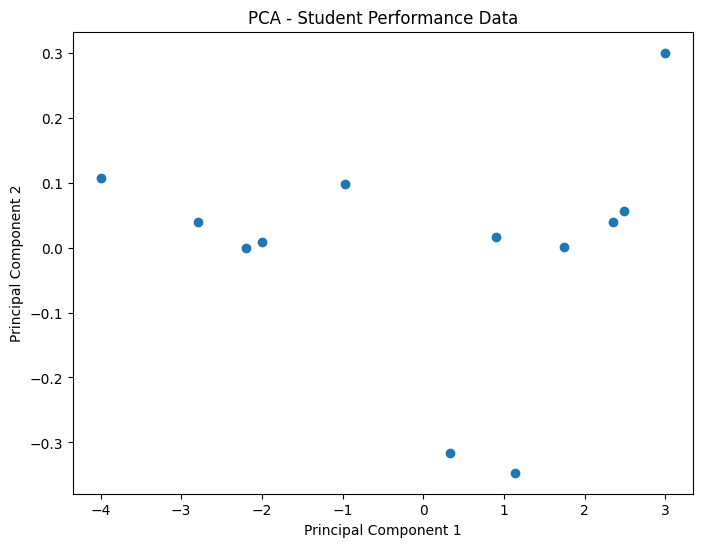

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(
    pca_df["Principal_Component_1"],
    pca_df["Principal_Component_2"]
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Student Performance Data")

plt.show()

In [9]:
pca_full = PCA()

pca_full.fit(X_scaled)

explained_variance = pca_full.explained_variance_ratio_

print("Explained Variance by Each Component:")

for i, variance in enumerate(explained_variance):
    print(f"Component {i+1}: {variance:.2%}")

Explained Variance by Each Component:
Component 1: 99.09%
Component 2: 0.56%
Component 3: 0.24%
Component 4: 0.07%
Component 5: 0.05%


In [10]:
cumulative_variance = np.cumsum(explained_variance)

print("Cumulative Explained Variance:")

for i, variance in enumerate(cumulative_variance):
    print(f"First {i+1} Components: {variance:.2%}")

Cumulative Explained Variance:
First 1 Components: 99.09%
First 2 Components: 99.65%
First 3 Components: 99.89%
First 4 Components: 99.95%
First 5 Components: 100.00%


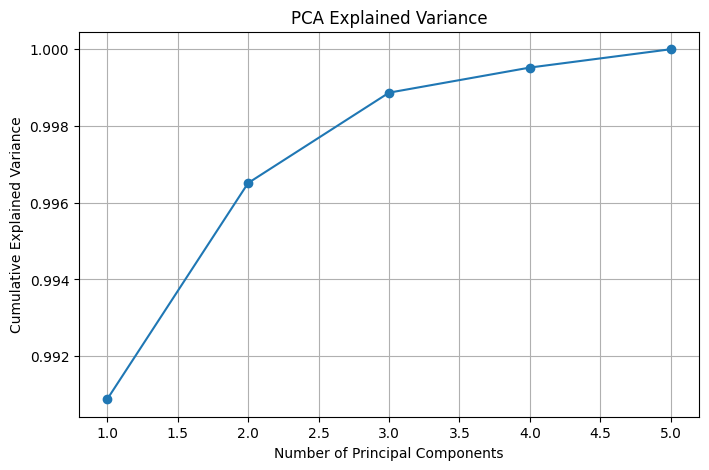

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")

plt.grid()
plt.show()

In [12]:
components = pd.DataFrame(
    pca.components_,
    columns=df.columns,
    index=["PC1", "PC2"]
)

components

,Study_Hours,Attendance,Assignments,Internal_Marks,Previous_Score
PC1,0.446243,0.447242,0.446387,0.448750,0.447442
PC2,0.595476,-0.426810,-0.568044,0.025302,0.374069


In [13]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=5
)

X_tsne = tsne.fit_transform(X_scaled)

print("Original Shape:", X_scaled.shape)
print("t-SNE Shape:", X_tsne.shape)

Original Shape: (12, 5)
t-SNE Shape: (12, 2)


In [14]:
tsne_df = pd.DataFrame(
    X_tsne,
    columns=["tSNE_1", "tSNE_2"]
)

tsne_df

,tSNE_1,tSNE_2
0,-1.752545,61.212715
1,-6.054507,46.825268
2,-1.207470,4.945410
3,2.820582,-12.071319
4,-1.177184,-48.058075
5,12.728765,65.868874
6,-0.015926,32.401287
7,-7.585905,-25.140139
8,-14.931439,-43.362015
9,8.143738,48.550648


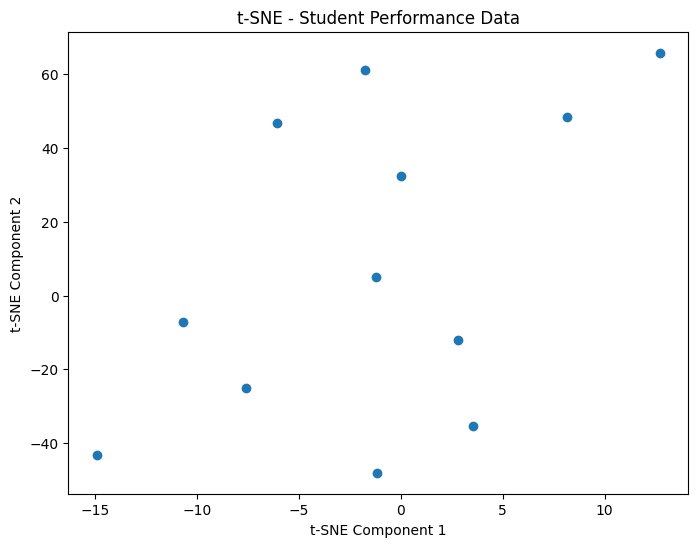

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(
    tsne_df["tSNE_1"],
    tsne_df["tSNE_2"]
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("t-SNE - Student Performance Data")

plt.show()

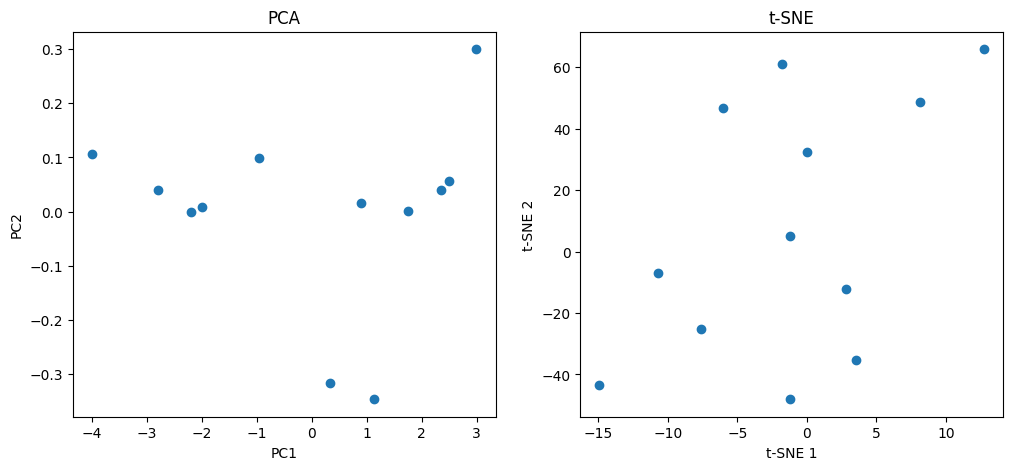

In [16]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.scatter(
    pca_df["Principal_Component_1"],
    pca_df["Principal_Component_2"]
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA")

plt.subplot(1, 2, 2)

plt.scatter(
    tsne_df["tSNE_1"],
    tsne_df["tSNE_2"]
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("t-SNE")

plt.show()